# Motion Blur: Linear and Shake
**DS 677 · Florence-2 vs. Specialist Models Under Motion Blur** · Vivek Shah and Victor Figueredo

The project's perturbation is **motion blur**: the blur a phone camera picks up when it moves while taking a photo, which is common for users who cannot see the screen. This notebook tests the shared blur code in `src/blur.py`, makes the example figure for the report, and checks on 50 images that blur really lowers a model's score.

Both blur types use one severity scale, **`blur_px`: how far the camera moves while the photo is taken, in pixels**. Levels are 0 (clean), 15, 30 and 45 px.

| Blur type | What it simulates |
|---|---|
| `linear` | The camera moves in a straight line, in a random direction |
| `shake` | The camera follows a random, curved path, like a shaking hand |

### What `src/blur.py` provides
| Function | What it does |
|---|---|
| `apply_blur(image, blur_type, blur_px, seed, image_id)` | Returns a motion-blurred copy of an image. `blur_px = 0` returns the image unchanged. |
| `make_kernel(blur_type, blur_px, seed, image_id)` | Returns the blur pattern (kernel) itself, used for figures and tests |

The blur for each image is fixed by `(seed, image_id)`, so Florence-2, BLIP and DETR all see exactly the same blurred picture. Each kernel sums to 1 (no brightening or darkening) and is centred, so blurring never moves objects away from their ground-truth boxes. `src/blur.py` only uses `numpy` and `PIL`, so no new packages are needed.

### What this notebook does
| What happens |
|---|
| Install packages and get the team's latest code |
| Download the detection data (~1 GB) |
| Test the blur module |
| Show every blur type and level, and save the figure for the report |
| Run DETR on 50 images at every blur level |

### Files this notebook produces
- `experiments/plots/blur_examples.png`: example figure of every blur type and level

## Step 1 · Install packages and get the team's code
- Installs the pinned packages. `transformers` and `timm` are needed for DETR in Step 5; `pycocotools` and `pycocoevalcap` for scoring.
- Clones the latest repo, which includes `src/blur.py`, and lets Python import from `src/`. It first moves to `/content`: deleting the folder the notebook is currently in would make the clone fail.

**Result:** the latest commit is shown. The pip warnings about `gradio` and `diffusers` are expected and harmless.

In [1]:
# Install pinned package versions
!pip install -q transformers==4.49.0 timm einops pycocotools==2.0.11 pycocoevalcap==1.2

# Step out of the repo folder first (deleting the current folder makes git clone fail)
%cd /content

# Remove any old copy of the repo, then download the latest version from GitHub
!rm -rf /content/repo
!git clone -q https://github.com/NJIT-DS677-Deep-Learning/florence2-vs-specialists-motion-blur.git /content/repo

# Move into the repo and show the latest commit
%cd /content/repo
!git log -1 --oneline

# Let Python import modules from src/
import sys
sys.path.insert(0, '/content/repo')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
/content
/content/repo
dbaad49 (HEAD -> main, origin/main, origin/HEAD) Prepare Florence-2 blur sweeps (awaiting shared blur implementation)


## Step 2 · Download the detection data
Only **val2017** images and **annotations** are needed here (~1 GB): the blur tests and the DETR check all use detection images. The captioning data is not needed in this notebook.

**Result:** downloaded in about 20 seconds. `/content/data` contains `annotations` and `val2017`.

In [2]:
# Create the data folder (outside the repo) and move into it
!mkdir -p /content/data
%cd /content/data

# Detection images and ground truth (all this phase needs)
!wget -q --show-progress http://images.cocodataset.org/zips/val2017.zip
!wget -q --show-progress http://images.cocodataset.org/annotations/annotations_trainval2017.zip

# Unpack and delete the zips
!unzip -q -o val2017.zip
!unzip -q -o annotations_trainval2017.zip
!rm -f *.zip

# Check what was downloaded, then go back to the repo
!ls /content/data
%cd /content/repo

/content/data
val2017.zip         100%[===================>] 777.80M  41.7MB/s    in 16s     
annotations_trainva 100%[===================>] 241.19M  60.2MB/s    in 4.4s    
annotations  val2017
/content/repo


## Step 3 · Test the blur module
Four checks on `src/blur.py`, using the first val2017 image:

- **Test 1:** `blur_px = 0` must return the original image untouched, so clean runs are exactly unchanged.
- **Test 2:** every kernel must sum to 1 (no brightening or darkening) and span about `blur_px` pixels.
- **Test 3:** the same seed and image must give an identical blur, and a different seed a different one.
- **Test 4:** blurring a single bright dot must leave it in the same place. If blur shifted the image, boxes would miss their objects and mAP would drop for the wrong reason.

**Result: all four tests passed.**

| Test | Expected | Got |
|---|---|---|
| 0 px unchanged | `True` | `True` |
| Kernel sum | 1.0000 for every level | 1.0000 for all 6 kernels |
| Kernel spread | about 15 / 30 / 45 px | linear 16.1 / 30.3 / 46.4 px; shake 16.2 / 31.6 / 45.5 px |
| Reproducible | identical; different seed differs | `True`; `True` |
| No shift (dot at 150, 100) | (150.0, 100.0) | linear (150.0, 100.0); shake (149.7, 100.2) |

The spread is about 1 px above the level because the path is drawn on a pixel grid. The shake dot moves by less than half a pixel, which is negligible.

In [3]:
import numpy as np
from PIL import Image
from src.blur import apply_blur, make_kernel
from src.config import BLUR_SETTINGS
from src.data import load_val2017, open_image

# Load val2017 and one test image
detection, coco = load_val2017()
x = detection[0]
img = open_image(x["path"])

# Test 1: 0 px leaves the image unchanged
print("0 px returns the original image:", apply_blur(img, "linear", 0, 0, x["image_id"]) is img)

# Test 2: every kernel sums to 1 and spans about blur_px
for blur_type, levels in BLUR_SETTINGS.items():
  for px in levels[1:]:
    k = make_kernel(blur_type, px, 0, x["image_id"])
    ys, xs = np.nonzero(k > 1e-6)
    points = np.stack([xs, ys], 1)
    spread = np.sqrt(((points[:, None] - points[None]) ** 2).sum(-1)).max()
    print(f"{blur_type:6s} {px:2d} px: kernel sum {k.sum():.4f}, spread {spread:.1f} px")

# Test 3: same seed and image give identical blur; a different seed gives a different blur
a = np.asarray(apply_blur(img, "shake", 30, 0, x["image_id"]))
b = np.asarray(apply_blur(img, "shake", 30, 0, x["image_id"]))
c = np.asarray(apply_blur(img, "shake", 30, 1, x["image_id"]))
print("Same seed identical:", (a == b).all(), "| Different seed differs:", (a != c).any())

# Test 4: blur does not shift the image (a single bright dot stays in place)
dot = np.zeros((200, 300, 3), np.uint8)
dot[100, 150] = 255
for blur_type in BLUR_SETTINGS:
  out = np.asarray(apply_blur(Image.fromarray(dot), blur_type, 45, 0, 1), dtype=float)[:, :, 0]
  yy, xx = np.indices(out.shape)
  print(f"{blur_type}: dot centre ({(out * xx).sum() / out.sum():.1f}, {(out * yy).sum() / out.sum():.1f}), expect (150.0, 100.0)")

loading annotations into memory...
Done (t=0.99s)
creating index...
index created!
0 px returns the original image: True
linear 15 px: kernel sum 1.0000, spread 16.1 px
linear 30 px: kernel sum 1.0000, spread 30.3 px
linear 45 px: kernel sum 1.0000, spread 46.4 px
shake  15 px: kernel sum 1.0000, spread 16.2 px
shake  30 px: kernel sum 1.0000, spread 31.6 px
shake  45 px: kernel sum 1.0000, spread 45.5 px
Same seed identical: True | Different seed differs: True
linear: dot centre (150.0, 100.0), expect (150.0, 100.0)
shake: dot centre (149.7, 100.2), expect (150.0, 100.0)


## Step 4 · Every blur type and level
Shows the first val2017 image at every level of both blur types, plus the camera path behind each `shake` level, and saves the figure as `experiments/plots/blur_examples.png` for the report.

**Result:**
- **Linear** blur smears the scene in one direction (here close to vertical), much like a photo taken while the phone was moving.
- **Shake** blur looks smudgier, with faint ghost copies of edges, because the camera path doubles back on itself.
- At **15 px** the scene is clearly blurred but every object is still easy to recognise. At **45 px** fine detail such as the people, chairs and vase is largely lost, while the overall room layout is still visible.
- The bottom row shows the shake paths: one smooth random path, rescaled to each level.

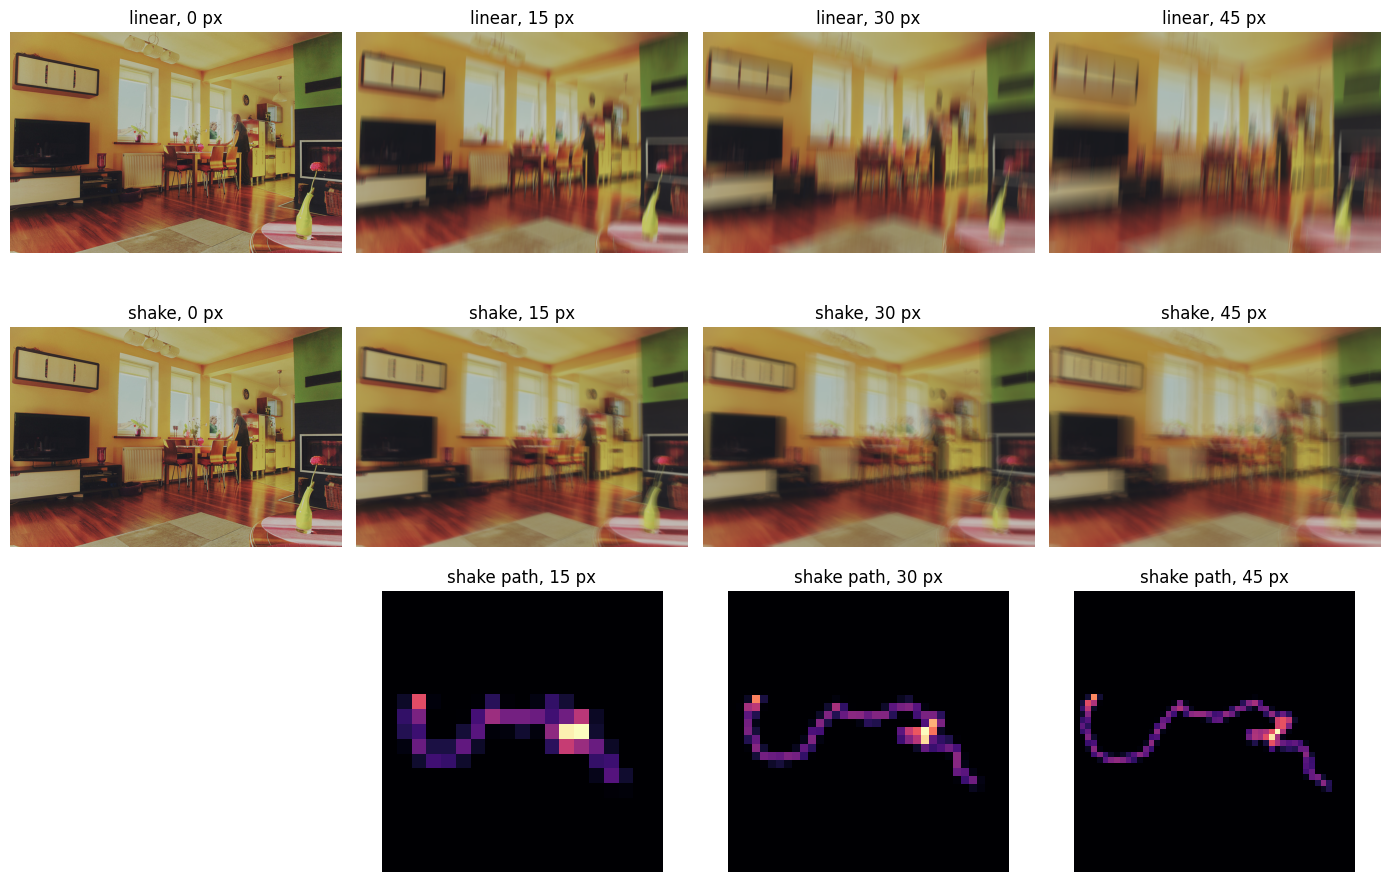

In [4]:
import os
import matplotlib.pyplot as plt

# One row per blur type, one column per level, plus a row showing the shake paths
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for col, px in enumerate(BLUR_SETTINGS["linear"]):
  for row, blur_type in enumerate(BLUR_SETTINGS):
    axes[row, col].imshow(apply_blur(img, blur_type, px, 0, x["image_id"]))
    axes[row, col].set_title(f"{blur_type}, {px} px")
  # Show the camera path behind each shake level
  if px:
    axes[2, col].imshow(make_kernel("shake", px, 0, x["image_id"]), cmap="magma")
    axes[2, col].set_title(f"shake path, {px} px")
for ax in axes.flat:
  ax.axis("off")
plt.tight_layout()

# Save the figure for the report
os.makedirs("experiments/plots", exist_ok=True)
plt.savefig("experiments/plots/blur_examples.png", dpi=150)
plt.show()

## Step 5 · DETR on 50 images at every blur level
Runs the whole pipeline (blur, then DETR, then the shared scorer) on the same 50 val2017 images used in the scoring notebook, at every blur type and level. This is a sanity check that blur lowers the score as expected, not a result: it uses one seed and 50 images.

**Result:**

| Blur | mAP | Relative drop |
|---|---|---|
| Clean | 46.8 | — |
| Linear 15 px | 22.2 | 52.5% |
| Linear 30 px | 5.8 | 87.7% |
| Linear 45 px | 3.6 | 92.3% |
| Shake 15 px | 32.0 | 31.7% |
| Shake 30 px | 16.8 | 64.0% |
| Shake 45 px | 11.7 | 75.1% |

- The clean score is **46.8**, exactly the same as in the scoring notebook, which confirms that `blur_px = 0` changes nothing.
- **mAP falls at every step** for both blur types, so the pipeline behaves as expected.
- **Linear blur hurts DETR more than shake blur** at the same `blur_px`. A shake path covers the same distance but doubles back, so part of each object stays sharp (the ghosting seen in Step 4), while a linear path smears every edge evenly.
- **DETR is very sensitive to blur:** it loses half its score at 15 px of linear blur and almost all of it by 30 px. If Florence-2 behaves similarly, the 30 and 45 px levels will show little difference between models, and lower levels (for example 5 and 10 px) would describe the curve better. This is worth checking with Florence-2 on the same 50 images before the full sweeps.

In [5]:
import contextlib, io
import torch
from transformers import DetrImageProcessor, DetrForObjectDetection
from src.evaluate import score_detections, to_coco_box

# Load DETR on the GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
detr_proc = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50")
detr = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50").to(device)

# Use the same 50 images as Phase 2
subset = detection[:50]
subset_ids = [x["image_id"] for x in subset]

def detr_map(blur_type, px):
  """Blur each image, run DETR, and return mAP (official protocol)."""
  dets = []
  for x in subset:
    img = apply_blur(open_image(x["path"]), blur_type, px, 0, x["image_id"])
    inputs = detr_proc(images=img, return_tensors="pt").to(device)
    with torch.no_grad():
      output = detr(**inputs)
    result = detr_proc.post_process_object_detection(output, threshold=0.0, target_sizes=[img.size[::-1]])[0]
    for score, label, box in zip(result["scores"], result["labels"], result["boxes"]):
      dets.append({"image_id": x["image_id"], "category_id": int(label),
                   "bbox": to_coco_box(box.tolist()), "score": float(score)})
  # Hide pycocotools' long printout
  with contextlib.redirect_stdout(io.StringIO()):
    return score_detections(dets, coco, subset_ids)["mAP"]

# Clean score, then every blur type and level
clean = detr_map("linear", 0)
print(f"clean        mAP {clean:5.1f}")
for blur_type, levels in BLUR_SETTINGS.items():
  for px in levels[1:]:
    m = detr_map(blur_type, px)
    print(f"{blur_type:6s} {px:2d} px  mAP {m:5.1f}  relative drop {(clean - m) / clean:6.1%}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


clean        mAP  46.8
linear 15 px  mAP  22.2  relative drop  52.5%
linear 30 px  mAP   5.8  relative drop  87.7%
linear 45 px  mAP   3.6  relative drop  92.3%
shake  15 px  mAP  32.0  relative drop  31.7%
shake  30 px  mAP  16.8  relative drop  64.0%
shake  45 px  mAP  11.7  relative drop  75.1%


## Summary
- **Blur module:** `apply_blur()` adds linear or shake motion blur on one scale (camera movement in pixels). Kernels sum to 1, are centred so boxes stay aligned, and are fixed per `(seed, image_id)`, so every model sees identical images. `blur_px = 0` leaves images unchanged.
- **Example figure:** `experiments/plots/blur_examples.png` shows every blur type and level, plus the shake paths.
- **DETR check:** on 50 images, DETR falls from 46.8 mAP (clean) to 22.2 / 5.8 / 3.6 under linear blur and 32.0 / 16.8 / 11.7 under shake blur at 15 / 30 / 45 px.
- **Blur levels:** linear blur is harsher than shake at the same level, and DETR nearly bottoms out by 30 px. Whether to add gentler levels should be decided once Florence-2 has been checked on the same images.